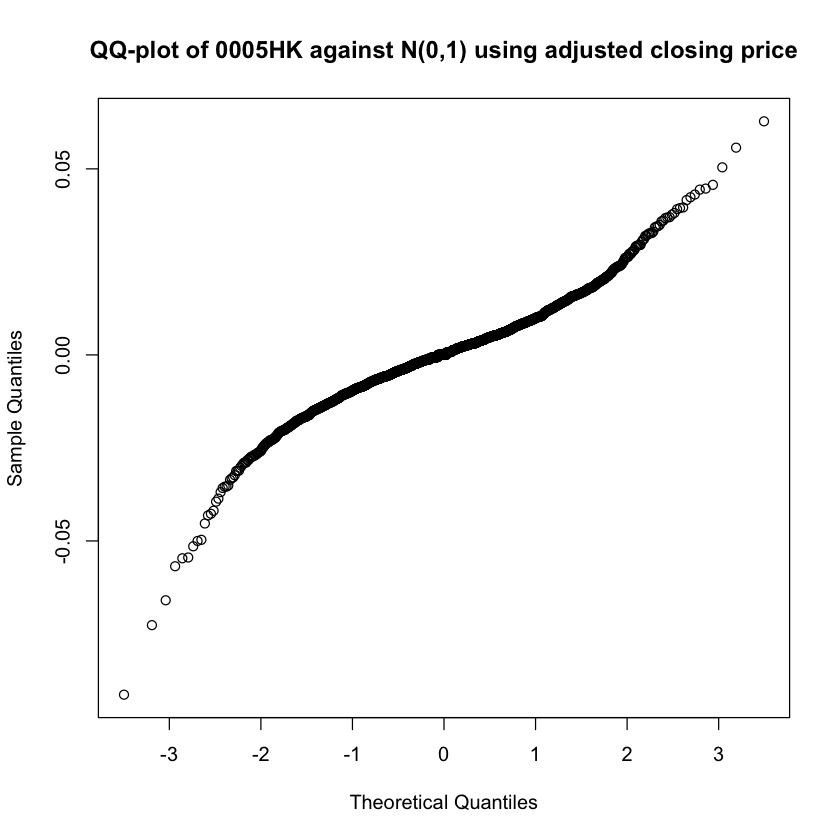

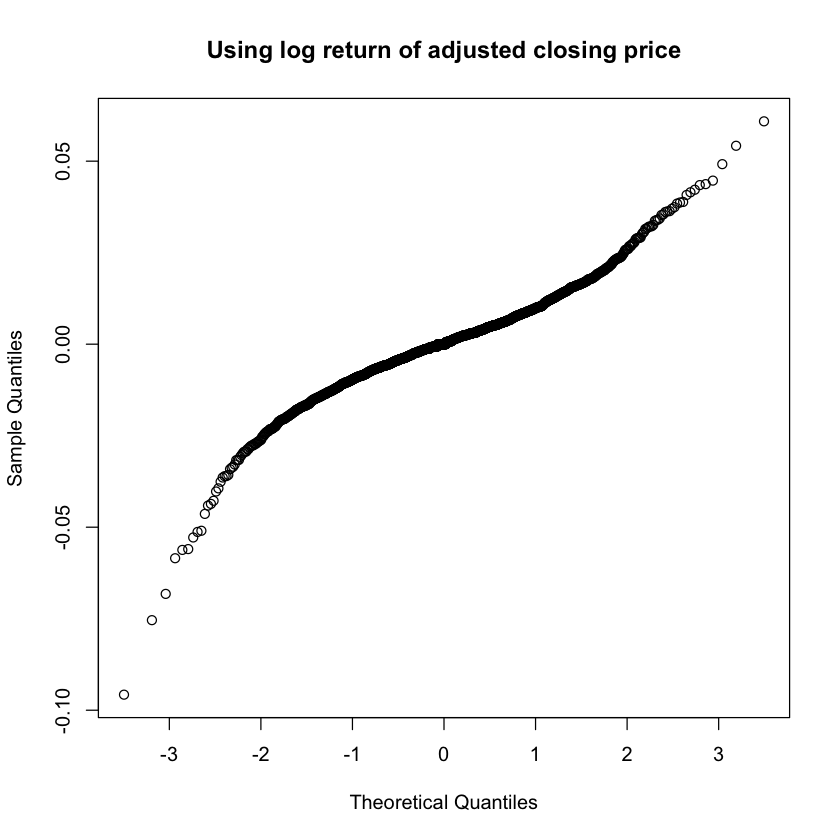

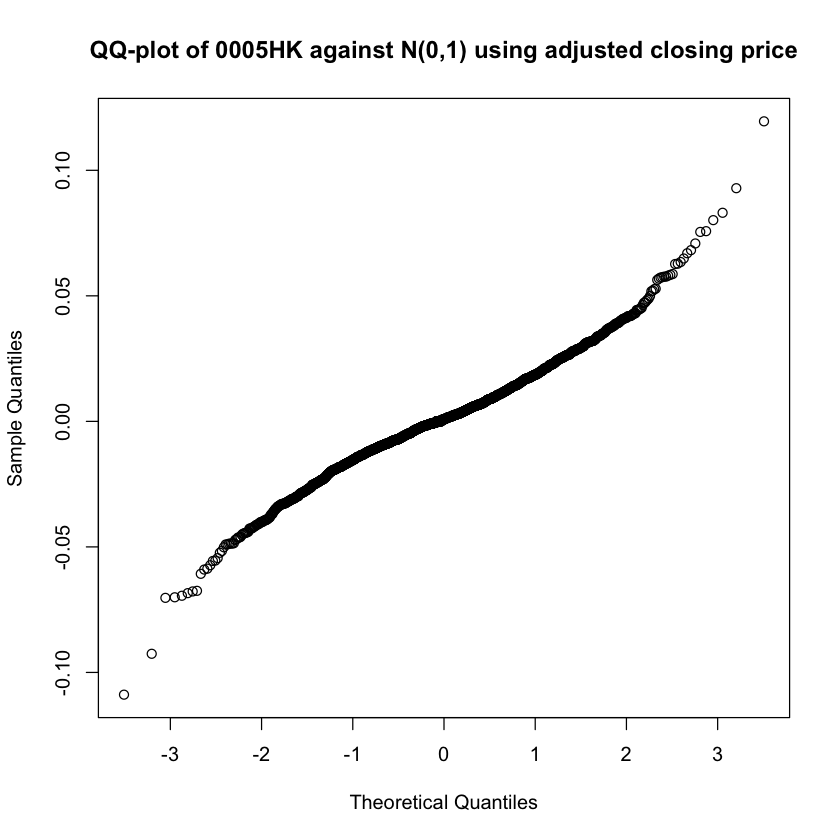

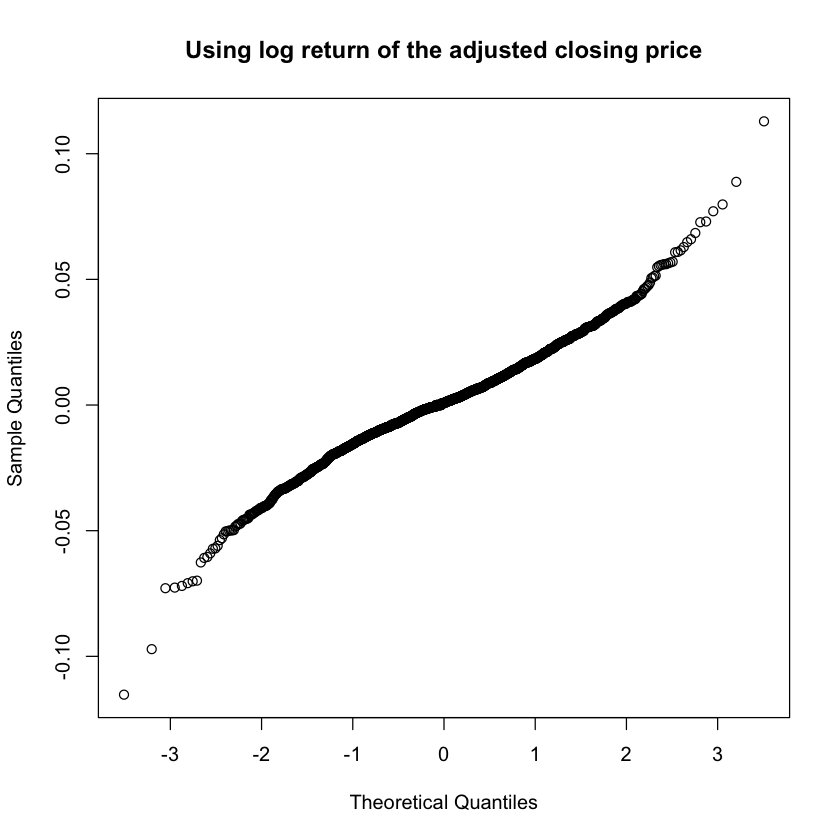

In [17]:
library(ggplot2)
library(readxl)

x0005hk <- read_excel("0005_HK.xlsx")
x0007hk <- read_excel("0700_HK.xlsx")

x0005hk_qq <- qqnorm(x0005hk$Return, main="QQ-plot of 0005HK against N(0,1) using adjusted closing price")
logret <- diff(log(x0005hk$`Adj Close`))
log_plot <- qqnorm(logret, main="Using log return of adjusted closing price")
x0005hk_qq <- qqnorm(x0007hk$Return, main="QQ-plot of 0005HK against N(0,1) using adjusted closing price")
logret <- diff(log(x0007hk$`Adj Close`))
log_plot <- qqnorm(logret, main="Using log return of the adjusted closing price")

In [ ]:
#KS tests
library(MASS)
library(readxl)
x0005hk <- read_excel("0005_HK.xlsx")
x0007hk <- read_excel("0700_HK.xlsx")
logret <- diff(log(x0005hk$`Adj Close`))
x <- logret + 1e-16 * rnorm(length(logret), 0, 1)
mles <- fitdistr(x, "normal")
ks.test(x, "pnorm", mean = mles$estimate["mean"], sd = mles$estimate["sd"])



	Asymptotic one-sample Kolmogorov-Smirnov test

data:  x
D = 0.062048, p-value = 1.745e-07
alternative hypothesis: two-sided


In [2]:
# Example 19
n <- 5

lambda_vals <- 1:5
m <- length(lambda_vals)
prior <- rep(0.2, m)

pi_list <- numeric(m) # The prior distribution of lambda
for (i in 1:n){
    pi_list[i] <- 0.2
}

pdf <- function(x, lambda){
    f_x <- lambda * exp(-lambda * x)
    return (f_x)
}
joint_density <- function(data, lambda){
    joint_dens <- prod(pdf(data, lambda))
    return(joint_dens)
    }
# The posterior distribution is calculated using Bayes' law: The prior distribution  * the joint conditional probabililty density function / probability of the data

posterior <- function(data, lambda_vals, prior) {
  num <- sapply(lambda_vals, function(l) joint_density(data, l)) * prior  # täljare per λ
  num / sum(num)                                                         # dela med P(data)
}

set.seed(1)
x <- rexp(10, rate = 2)
posterior(x, lambda_vals, prior)

[1] 0.03034164 0.45984152 0.39245502 0.10314457 0.01421725

In [4]:
# Example 20
library(MASS)
aic <- function(data, distribution) {
  fit <- fitdistr(data, distribution)
  ll  <- logLik(fit)                    # maximalt loglikelihoodvärde, med attributet df = k
  k   <- attr(ll, "df")
  c(loglik = as.numeric(ll), k = k, AIC = -2 * as.numeric(ll) + 2 * k)
}

set.seed(1)
x <- rexp(1e6, rate = 0.025)
sapply(c("exponential", "normal", "lognormal"), function(d) aic(x, d))

,exponential,normal,lognormal
loglik,-4689665,-5108449,-4780526
k,1,2,2
AIC,9379332,10216903,9561057


In [13]:
# Example 21
library("Rfast")
library("ramify")
library("LambertW")
library("readxl")
data <- read_excel("0700_HK.xlsx")
x <- diff(log(data$`Adj Close`))
x <- na.omit(x)
x <- as.matrix(x) # ensure the data is in matrix form
df <- seq(2, 8, 0.001) # set the range for candidate degrees of freedom for t-distribution
n <- length(df)
loglik <- rep(0, n) #used to store the log likelihood for the different degrees of freedom

for (i in 1:n){
    fitresult <- mvt.mle(x, df[i])
    loglik[i] <- fitresult$loglik
}
loglik_value <- loglik[which.max(loglik)]
AIC <- -2*loglik_value + 2*3 #Three is the number of parameters for the t distribution
print(AIC)

# AIC for the normal distribution
aic_normal <- aic(as.numeric(x), "normal")
print(aic_normal["AIC"])

[1] -11304.19
      AIC 
-11150.61 


In [9]:
# Monte Carlo Simulation
# We want to sample from a lognormal distribution with mean = 2 and SD = 1 to estimate the second moment
n_list <- c(100, 1000, 10000, 100000, 1000000)
m <- 3
estimates <- matrix(0, nrow = length(n_list), ncol = m)
se <- matrix(0, nrow = length(n_list), ncol = m)
for (i in 1:length(n_list)){
    n = n_list[i]
    for (j in 1:m){
        x <- rlnorm(n, meanlog = 2, sdlog = 1)
        mu <- mean(x**2)
        estimates[i,j] <- mean(x**2)
        se[i, j] <- sqrt(1 / n * (1 / (n - 1) * sum((x**2 - mu)**2)))
    }
}

estimates
se

319.9531,620.9559,234.1219
497.3934,328.9953,401.1644
420.5599,411.3495,365.8645
400.4985,396.8652,400.9162
402.0681,401.4533,405.4480


60.503508,355.381848,52.715657
81.544666,32.763671,83.482868
30.139463,23.943173,14.900555
6.908782,7.874234,6.494223
2.561630,2.601699,2.879064


In [10]:
# Monte Carlo Simulation for pricing call options
N <- 1e6
S0 <- 100
X <- 110
sigma <- 0.2
r <- 0.03
T <- 1
VT <- rep(0,N)

for (i in 1:N){
    WT <- rnorm(1, 0, sd = sqrt(T))
    ST <- S0 * exp((r - sigma ** 2 / 2) * T + sigma * WT)
    VT[i] <- exp(-r*T) * max(ST - X, 0)
}

estimate <- mean(VT)
SE <- sd(VT) / sqrt(n)
PE <- SE / estimate

estimate; SE; PE

[1] 5.295514

[1] 0.0109644

[1] 0.002070507

In [ ]:
# Application of analysing risk in P and C Insurance
# Total claim is S = X1 + X2 + ... + XN 
# Xi follows f_X(x) = 3 / x ** 4
# N follows P_N(k) = lambda ** k * exp(-lambda) / factorial(k)
# lambda = 4

# a) We want to calculate the expected value of S. The theoretical is E(S) = E(X)E(N) = 6
# b) We want to calculate the probabililty that S > 10
# c) We want to calculate the 95% quantile, also known as value at risk at 95%

cdf_x_inv <- function(U){
    return (1 / (U ** (1 / 3)))
}
iterations <- 100000
S <- rep(0, iterations)
S10 <- rep(0, iterations)
for (i in 1:iterations){
    N <- rpois(1, 4)
    U <- runif(N, 0, 1)
    S[i] <- sum(cdf_x_inv(U))
    S10[i] <- if (S[i] > 10) 1 else 0
}
estimate <- mean(S)
SE <- sd(S) / sqrt(iterations)
PE <- SE / estimate
Prob10 <- mean(S10)
sorted <- sort(S)
p95 <- sorted[0.95 * iterations]
estimate; SE; PE; Prob10; p95

[1] 6.008395

[1] 0.01098569

[1] 0.00182839

[1] 0.11757

[1] 12.1765

In [22]:
# Profitability of a dynamic trading strategy
set.seed(1)
log_r <- 0.00015
log_mu <- 0.0011
lambda <- 0.00153
v <- 4.7 
days <- 30
return_goal <- 0.02
iterations <- 100000
tot_return <- rep(0, iterations)
# Initially 50% of the capital in bonds and 50% in stocks
# If the stock return is positive the investor will invest 70% of the capital in stocks
# If it is negative it will invest 30% of the capital in stocks

for (iter in 1:iterations){
    initial_capital <- 100
    stocks <- 0.5 * initial_capital
    bonds <- 0.5 * initial_capital
    for (i in 1:days){
        bonds <- bonds * exp(log_r)
        log_return <- log_mu + lambda * rt(1, df = v)
        stocks <- stocks * exp(log_return)
        capital <- stocks + bonds
        if (log_return < 0) stocks <- capital * 0.3 else stocks <- capital * 0.7
        bonds <- capital - stocks
    }
    capital <- stocks + bonds
    tot_return[iter] <- (capital / initial_capital - 1) 
}
prob_success <- mean(tot_return > return_goal)

success <- as.numeric(tot_return > return_goal)
SE <- sd(sucess) / sqrt(iterations)
PE <- SE / prob_sucess
prob_success; SE; PE


[1] 0.58172

[1] 0.001558022

[1] 0.002678303

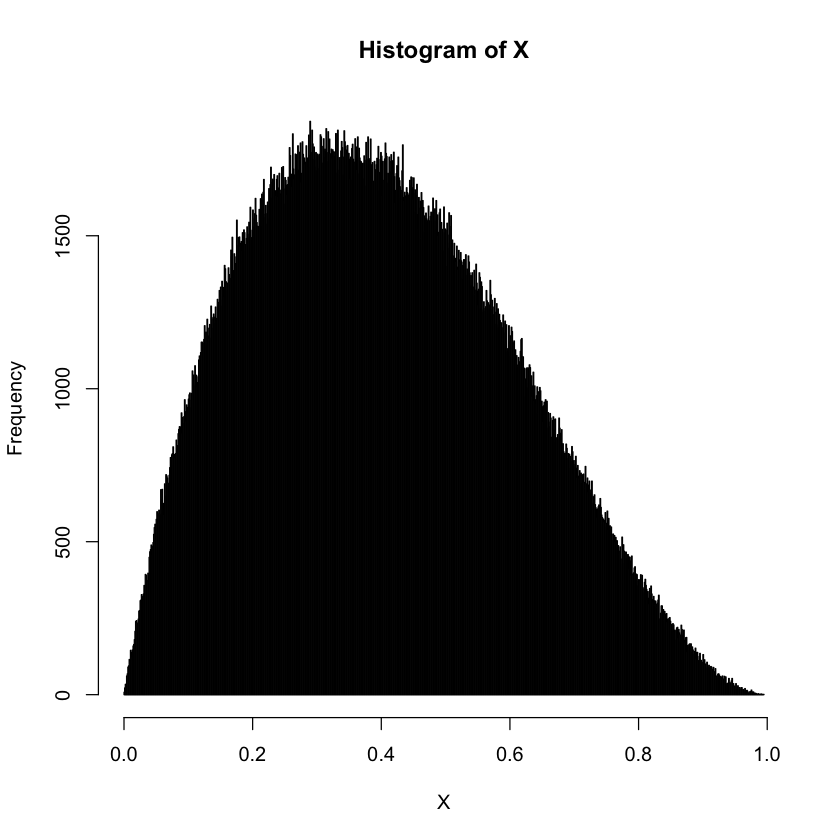

In [28]:
# Example 6 rejection sampling. X follows a beta distribution
N <- 1000000
a <- 2
b <- 3
X <- rep(0, N)
i <- 1
counter <- 0
M <- gamma(a + b) / (gamma(a) * gamma(b)) * ((a - 1) / (a + b - 2)) ** (a - 1) * ((b - 1) / (a + b - 2)) ** (b - 1)
while (i < N){
    counter <- counter + 1
    x <- runif(1, min = 0, max = 1) #same support as f_X(x)
    y <- runif(1, min = 0, max = 1)
    threshold <- ((gamma(a + b)/(gamma(a) * gamma(b))) * x ** (a - 1) * (1 - x) ** (b - 1)) / M
    if (y <= threshold){
        X[i] <- x #keep the sample if it is not rejected
        i <- i + 1 #we only update if the sample is accepted. we want N samples
    }
}
hist(X, breaks = 1000)

In [31]:
# Example 7 Calculating the second moment
n <- 1000000
X <- rep(0, n)
Y <- rep(0, n) # We store the square of the observations here
i <- 1
M <- sqrt(2 * pi) * exp(1 / 16)
while (i < n){
    x <- rnorm(1, 0, 1)
    y <- runif(1, 0, 1)
    threshold <- sqrt(2 * pi) / M * exp(-x ** 4 + x**2 / 2)
    if (y <= threshold){
        X[i] <- x
        Y[i] <- x ** 2
        i <- i+1
    }
}
estimate <- mean(Y)
SE <- sd(Y) / sqrt(n)
PE <- SE / estimate
estimate; SE; PE

[1] 0.3381937

[1] 0.0003687242

[1] 0.001090275

In [ ]:
# Example 9 Using importance sampling to compute the expected value of X
# X follows a distribution with support between 0 < x < 1. We want to compute the expected value by considering the density of the uniform distribution
n <- 1000000
# Parameters of the distribution of X
a <- 2
b <- 2 
pdfdist <- function(x, a, b){
    pdf <- (gamma(a+b) / gamma(a) * gamma(b)) * x ** (a - 1) * (1 - x) ** (b - 1)
    return (pdf)
}

X <- runif(n, min = 0, max = 1)
Y <- X * pdfdist(X, a, b) / 1 # the density of U(0, 1) is just 1
estimate <- mean(Y)
SE <- sd(Y) / sqrt(n)
PE <- SE / estimate

estimate; SE; PE


[1] 0.49989

[1] 0.0003049116

[1] 0.0006099574

In [37]:
# Example 10 Application of Importance Sampling

St <- function(S0, mu, sigma, t, Wt){
    St <- S0 * exp((mu - sigma ** 2 / 2) * t + sigma * Wt)
    return (St)
}

Vt <- function(St, K){
    payoff <- pmax(St - K, 0)
    return (payoff)
}

# When using the risk-neutral probability measure we replace mu with rf when calculating St
# This will result in two little scenarios when ST > X. We want to change the distribution such that this happens more often. We also need to count the number of times this occur
# We choose g_wt(X) to be a normal distribution with mean greater than 0 and variance X

mu <- function(S0, r, sigma, T, X){
    mean <- ((log(X / S0) - (r - sigma ** 2 / 2) * T) / sigma)
    return (mean)
}

# Parameters
iterations <- 10000000
S0 <- 100
X <- 250
sigma <- 0.2
r <- 0.03
T <- 1
VT <- rep(0, iterations) #store the payoff of the call option for a single simulation
counter <- 0 # We want to count the number of samples such that ST > X. 
mu <- mu(S0, r, sigma, T, X)

# We want to test both the old distribution f (centered normal) and the new distribution g of WT
fx <- function(X, T){1 / sqrt(2 * pi * T) * exp(-(X) ** 2 / (2 * T))}
gx <- function(X, T, mu){1 / sqrt(2 * pi * T) * exp(-(X - mu) ** 2 / (2 * T))}

WT <- rnorm(iterations, mu, sqrt(T))
ST <- St(S0 , mu = r, sigma, T, WT)
VT <- exp(-r * T) * Vt(ST, K = X) * fx(WT, T) / gx(WT, T, mu)
counter <- sum(ST > X)
estimate <- mean(VT)
SE <- sd(VT) / sqrt(iterations)
PE <- SE / estimate
percentage <- counter / iterations
estimate; SE; PE; percentage



[1] 3.004185e-05

[1] 1.460134e-08

[1] 0.0004860332

[1] 0.4999102

In [38]:
# Example 11, revisiting example 3 with antithetic sampling
# We want to calculate the expected payoff for a call option
N <- 100000
S0 <- 100
X <- 110
sigma <- 0.2
r <- 0.03
T <- 1
VT <- rep(0, N)

# Here the asset price at time T is a function of the Brownian motion WT
for (i in 1:N){
    WT <- rnorm(1, 0, sd = sqrt(T))
    ST <- S0 * exp((r - sigma ** 2 / 2) * T + sigma * WT)
    STA <- S0 * exp((r - sigma ** 2 / 2) * T - sigma * WT) # The antithestic sample
    VT[i] <- exp(-r * T) * (Vt(ST, X) + Vt(STA, X)) / 2
}

estimate <- mean(VT)
SE <- sd(VT) / sqrt(N)
PE <- SE / estimate

estimate; SE; PE

[1] 5.32702

[1] 0.02146791

[1] 0.004030004

In [40]:
# Example 12 – Effectiveness of bootstrapping
# We draw a random sample from a log-normal distribution with mu = 0, sigma = 1
# We consider the point estimate theta for the mean. We want to calculate the expected value, variance and bias of the point estimate

n <- 50000
B <- 100000
x <- rlnorm(n, 0, 1)
theta_hat <- mean(x) # point estimate of the mean
theta_boot <- rep(0, B) #placeholder for the bootstrapped point estimate sample
for (i in 1:B){
    boot_sample <- sample(x, n, replace = TRUE)
    theta_boot[i] <- mean(boot_sample)
}
mean_theta <- mean(theta_boot)
sd_theta <- sqrt((1 / (B - 1)) * sum((theta_boot - mean_theta) ** 2))
bia_theta <- mean_theta - theta_hat

mean_theta; var_theta; bia_theta


[1] 1.64028

[1] 2.094512e-28

[1] -1.072231e-06

In [43]:
# Example 13 Estimating MSE of Maximum Likelihood Estimate
lambda <- 3
n <- 10000
B <- 50000
library(MASS)
library(boot)
x <- rpois(n, lambda)
mle_results <- fitdistr(x, "Poisson") #Standard mle results to get lambda
# Now we want to create a function to get the mle estimate for the lambda of the bootstrapped samples
poisson_mle <- function(x, indices){
    y <- fitdistr(x[indices], "Poisson")[["estimate"]]
    return (y)
}
boot_results <- boot(x, poisson_mle, R = B) # the estimation of lambda using bootstrapping
mle_results
boot_results 

     lambda  
  3.02100000 
 (0.01738102)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = x, statistic = poisson_mle, R = B)


Bootstrap Statistics :
    original    bias    std. error
t1*    3.021 7.673e-05  0.01756654

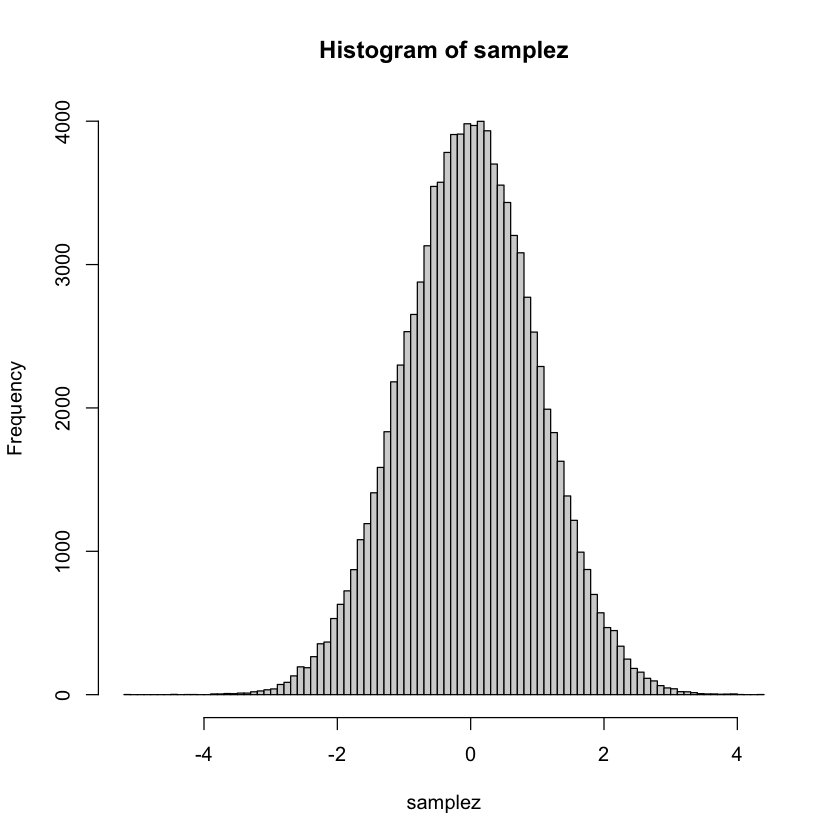

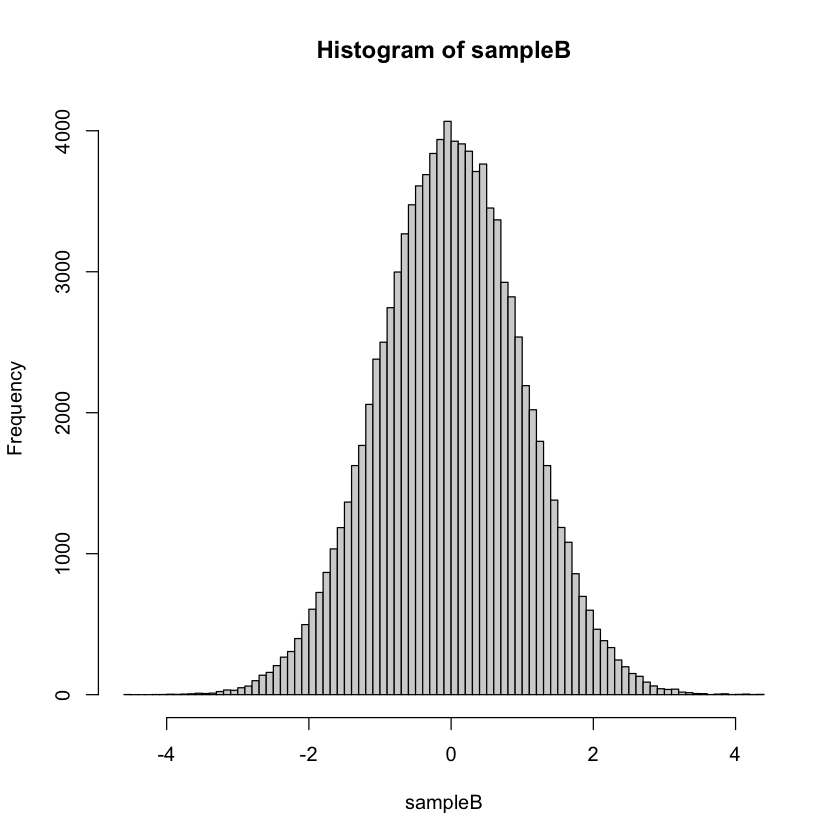

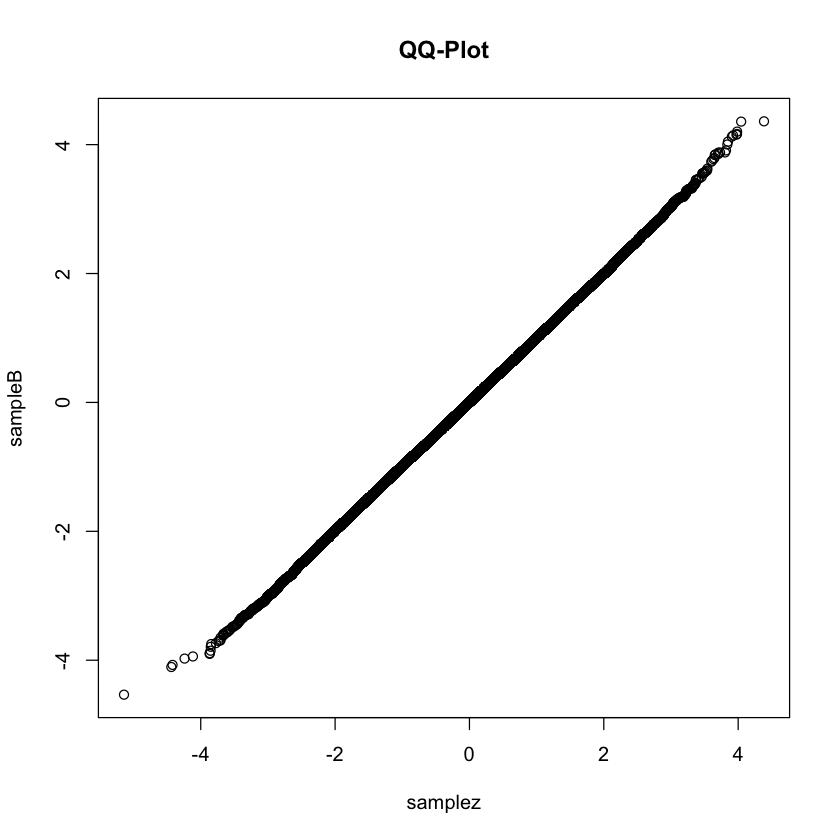

In [46]:
# Example 13 continued
# We consider two cases, first that the sampels are drawn from a normal distribution and secondly when it is from an exponential distribution
# We want to calculate the T-statistic when drawing from the original distribution vs when bootstrapping
n <- 10000
B <- 100000
mu <- 2
sigma <- 1
samplez <- rep(0, B) # We store the results when drawing from the true distribution
sampleB <- rep(0, B) # We store the results when redrawing from the first sample

x <- rnorm(n, mean = mu, sd = sigma) # Generate data for bootstrap
t_stat <- function(mean, mu, sd, n){
    t_val <- (mean - mu) / (sd / sqrt(n))
    return (t_val)
}

for (i in 1:B){
    y <- rnorm(n, mu, sd = sigma)
    samplez[i] <- t_stat(mean(y), mu, sigma, n)
    z <- sample(x, n, replace = TRUE)
    sampleB[i] <- t_stat(mean(z), mean(x), sd = sd(z), n)
}

hist(samplez, breaks = 100)
hist(sampleB, breaks = 100)
qqplot(samplez, sampleB, main = "QQ-Plot")

In [66]:
# Example 14
library(readxl)
B <- 10000
x0005hk <- read_excel("0005_HK.xlsx")
logret <- na.omit(diff(log(x0005hk$'Adj Close')))
n <- length(logret)
log_mu <- mean(logret)
T_boot <- rep(0, B)
for (i in 1:B){
    xboot <- sample(logret, n, replace = TRUE)
    T_boot[i] <- (mean(xboot) - log_mu) / (sd(xboot) / sqrt(n))
}
tl <- quantile(T_boot, 0.025)
tu <- quantile(T_boot, 0.975)
se <- sd(logret) / sqrt(n)
ci <- c(log_mu - tu * se, log_mu - tl * se)
ci; tl; tu


# Hypothesis testing to see if the average return is positive
average_return <- mean(exp(logret) - 1)
log_mu
# The null hypothesis is mu <= 0
# We reject the null hypothesis if the t-statistic is large enough
# Given a confidence level alpha we get a corresponding threshold
threshold <- quantile(T_boot, 0.95)
T_stat <- (log_mu - 0) / (sd(logret) / sqrt(n))
threshold
T_stat

97.5%          2.5% 
-0.0004133860  0.0006228681

2.5% 
-1.965239

97.5% 
1.927604

[1] 9.973188e-05

95% 
1.659623

[1] 0.3746577

In [68]:
# Example 15 Parametric Bootstrapping
n <- 10000
B <- 100000
x <- rnorm(n, 0, 1)
theta_point <- mean(x)
theta_boot <- rep(0, B)
mles <- as.vector(fitdistr(x, "Normal")$estimate)
mlemu <- mles[[1]]
mlesigma <- mles[[2]]
for (i in 1:B){
    y <- rnorm(n, mlemu, mlesigma)
    theta_boot[i] <- mean(y)
}
mean_theta <- mean(theta_boot)
bias_theta <- mean_theta - theta_point
sd_theta <- sd(theta_boot)

mean_theta; bias_theta; sd_theta



[1] -0.005079055

[1] -1.379943e-05

[1] 0.01000744